# Keskar et al. (ICLR 2017), Figure 3 (F1, C1, C2): reproduction

All training, interpolation and plotting code (`phase1.py`, `phase3.py`) was written by **Claude Sonnet 5.5 (Medium effort) in the
claude.ai chat interface**; the full conversation is in `llm_transcript.md`. This notebook only calls those scripts and shows their outputs.

Setup: Adam (lr 1e-3), SB batch 256, LB batch 5000 (10% of the data), shared initialisation, training until the full-train loss stops
improving by 1% for 10 epochs (C2 capped at 40 epochs), then f(α x_LB + (1-α) x_SB) for α in [-1, 2] (61 points) with BatchNorm
statistics recomputed on the training set at every α.

CIFAR-10 note: see `../tools/run_patched.py` (it disables only torchvision's md5 check for our Hugging Face copy of CIFAR-10).

In [1]:
import subprocess, sys
from pathlib import Path
from IPython.display import Image, display

HERE = Path.cwd()                      # run this notebook from its own folder
PY = sys.executable
RUN_TRAINING = False                   # True = retrain from scratch (hours on a laptop GPU)

def run(*args):
    """Run one of the LLM-generated scripts and stream its output."""
    cmd = [PY, *map(str, args)]
    print("$", " ".join(cmd))
    subprocess.run(cmd, cwd=HERE, check=True)

def show_csv(path):
    import csv
    rows = list(csv.reader(open(path)))
    w = [max(len(r[i]) for r in rows) for i in range(len(rows[0]))]
    for r in rows:
        print("  ".join(c.ljust(n) for c, n in zip(r, w)))

## 1. Training + interpolation (skipped by default; results are in `phase3_runs/*/curve.json`)

In [2]:
if RUN_TRAINING:
    run("../tools/run_patched.py", "phase3.py", "all", "--panels", "F1", "C1", "--c1_variant", "both",
        "--out", "phase3_runs", "--data_root", "../data")
    run("../tools/run_patched.py", "phase3.py", "all", "--panels", "C2", "--cap", "C2:sb=40", "--cap", "C2:lb=40",
        "--stop_eval_every", "5", "--out", "phase3_runs", "--data_root", "../data")

## 2. Figure 3 from the saved curves

In [3]:
run("phase3.py", "plot", "--panels", "F1", "C1", "C2", "--c1_variant", "both", "--out", "phase3_runs")

$ /Volumes/Projects/CS_6362-Advanced_Machine_Learning/assignment2/.venv/bin/python phase3.py plot --panels F1 C1 C2 --c1_variant both --out phase3_runs


device: mps torch: 2.14.1
saved phase3_runs/figure3_reproduction.png


### Reproduction (top) vs. original (bottom; the paper's panels F1, F2, C1, C2)
Panel (c) "C1 collapse" is the Phase 1 reading of the C1 architecture, kept as an ablation. Panel (b) is the architecture confirmed by the
authors' code.

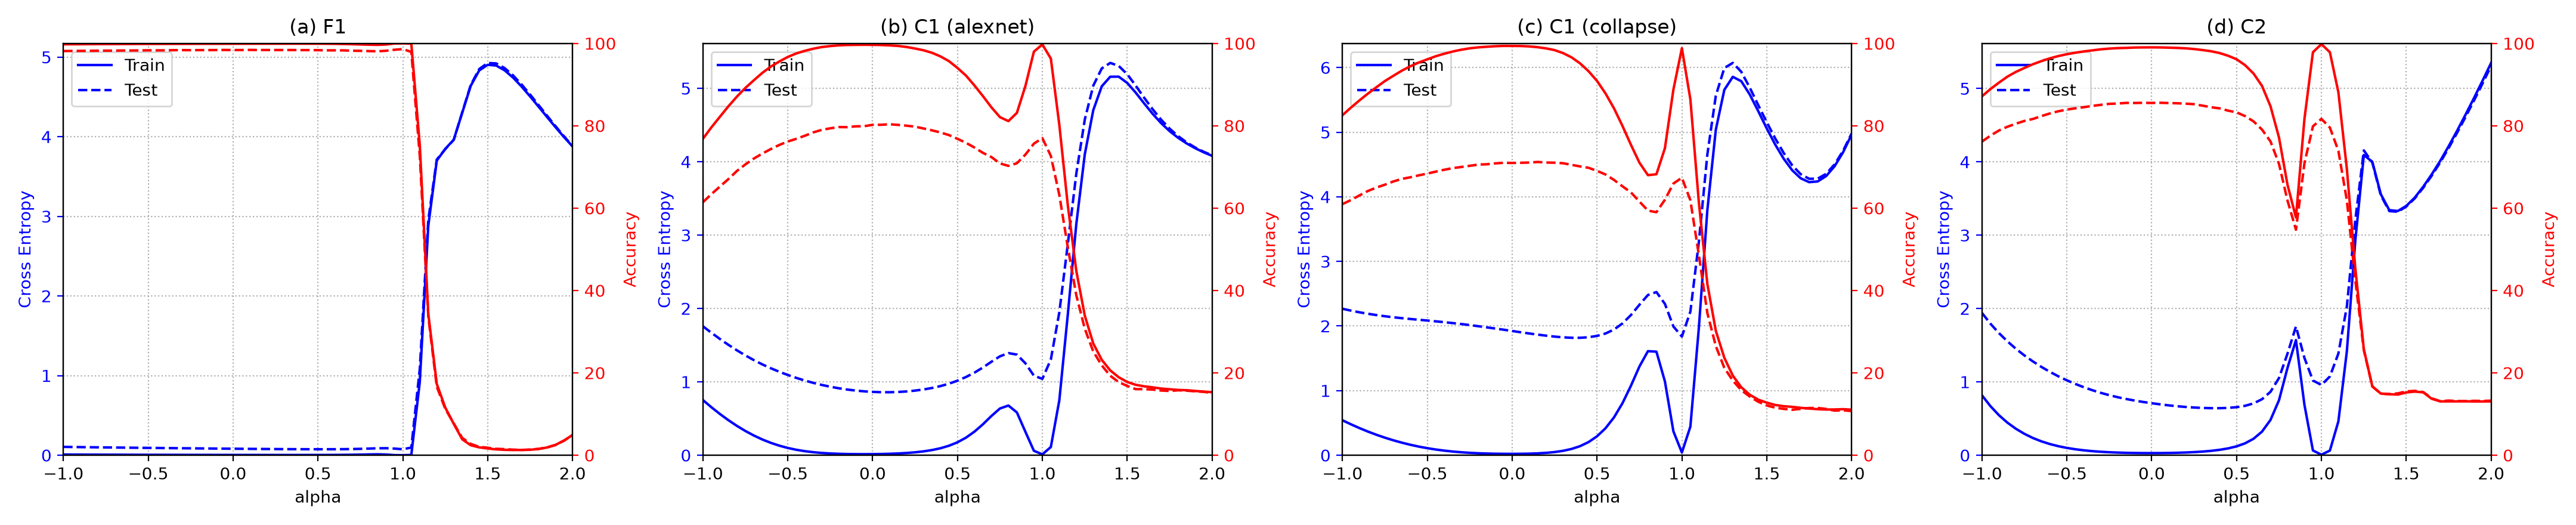

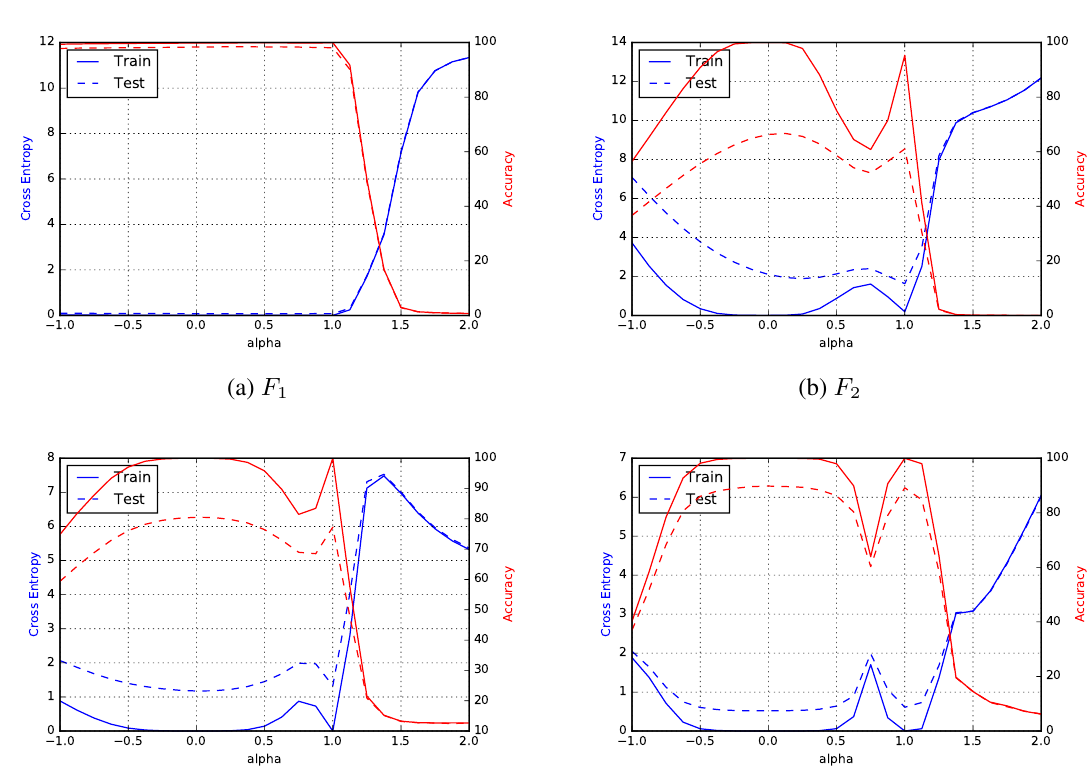

In [4]:
display(Image("phase3_runs/figure3_reproduction.png"))
display(Image("original_figure3.png"))

## 3. Phase 4 diagnostic: interpolated vs. recomputed BatchNorm statistics
Same saved models, evaluated with `--bn_mode interp` (no retraining). See `phase4.md`.

$ /Volumes/Projects/CS_6362-Advanced_Machine_Learning/assignment2/.venv/bin/python phase3.py plot --panels F1 C1 C2 --c1_variant alexnet --out ablation_bn_interp


device: mps torch: 2.14.1
saved ablation_bn_interp/figure3_reproduction.png


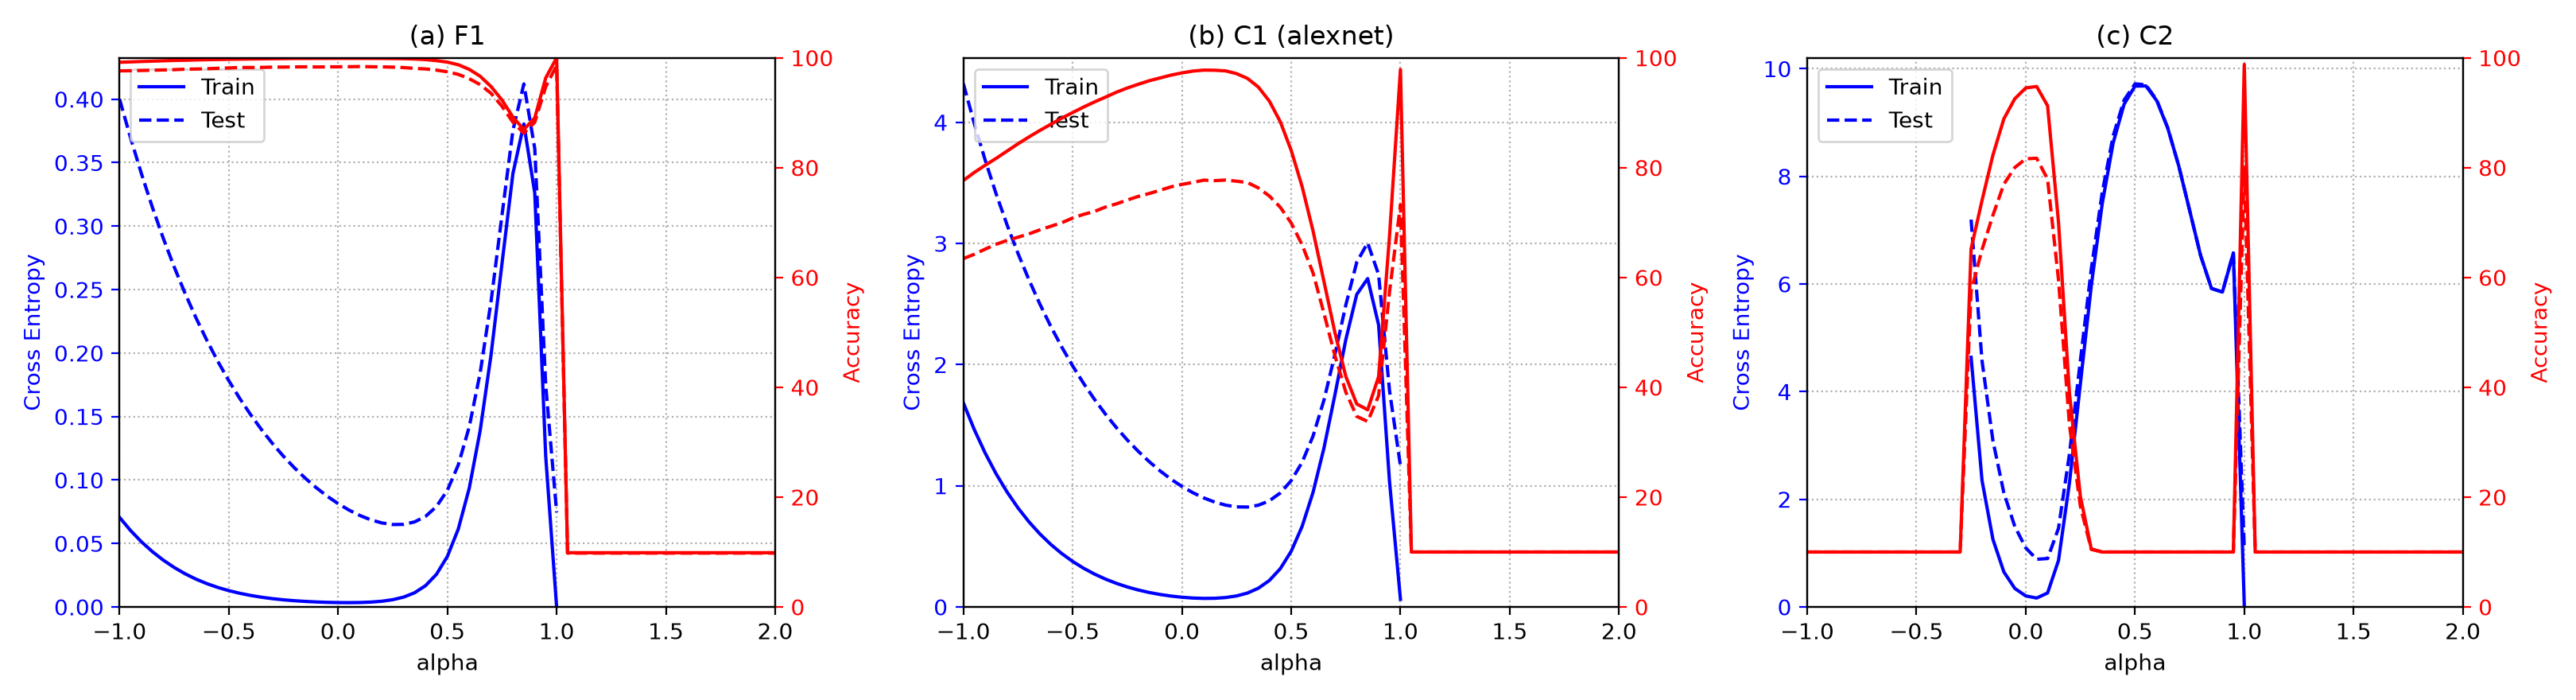

In [5]:
if RUN_TRAINING or not (HERE / "ablation_bn_interp/C2/curve.json").exists():
    subprocess.run(["bash", "ablation_bn_interp/run.sh"], cwd=HERE, check=True)
run("phase3.py", "plot", "--panels", "F1", "C1", "C2", "--c1_variant", "alexnet", "--out", "ablation_bn_interp")
display(Image("ablation_bn_interp/figure3_reproduction.png"))

In [6]:
import json
for d in ("phase3_runs", "ablation_bn_interp"):
    for p in ("F1", "C1_alexnet", "C2"):
        c = json.load(open(f"{d}/{p}/curve.json"))
        inside = [i for i, a in enumerate(c["alpha"]) if 0 <= a <= 1 + 1e-9]
        i = max(inside, key=lambda i: c["train_loss"][i])
        print(f"{d:19s} {p:11s} peak train loss on [0,1]: {c['train_loss'][i]:.3f} at alpha={c['alpha'][i]:.2f} "
              f"(train acc {c['train_acc'][i]:.1f}%)")

phase3_runs         F1          peak train loss on [0,1]: 0.011 at alpha=0.85 (train acc 99.6%)
phase3_runs         C1_alexnet  peak train loss on [0,1]: 0.677 at alpha=0.80 (train acc 81.1%)
phase3_runs         C2          peak train loss on [0,1]: 1.569 at alpha=0.85 (train acc 57.7%)
ablation_bn_interp  F1          peak train loss on [0,1]: 0.380 at alpha=0.85 (train acc 86.9%)
ablation_bn_interp  C1_alexnet  peak train loss on [0,1]: 2.710 at alpha=0.85 (train acc 35.9%)
ablation_bn_interp  C2          peak train loss on [0,1]: 9.680 at alpha=0.55 (train acc 10.0%)
